In [48]:
# import a pickle file and see what it is inside
import pickle
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import cv2
# import deeplabcut as dlc
import scipy.io

session = r'241125'
model_path = r'G:\My Drive\_Code\DLC-models\monocular-calibration-2024-11-21\videos'
model_name = r'DLC_resnet50_monocularNov21shuffle1_10500'
data_path = r'D:\data-distance-coding-project\calibration'
data_path = os.path.join(data_path, session)

# import also the video file and extract the frames
video_filename = session + '.mp4'
# df_filename = session + model_name + '.h5'

# now extract the frames
cap = cv2.VideoCapture(os.path.join(data_path, video_filename))
video_frames = []
while True:
    ret, frame = cap.read()
    if not ret:
        break
    video_frames.append(frame)
cap.release()

# in the data folder there is a matlab file
from scipy.io import loadmat
frame_filename = session + '_timestamps.mat'
frame_timestamp = loadmat(os.path.join(data_path, matlab_filename))
frame_timestamp = frame_timestamp['frame_timestamp'][0][:877]

data_filename = session + '_data.mat'
data = loadmat(os.path.join(data_path, data_filename))
steps = data['stim_data']['steps'][0][0][0]
time = data['stim_data']['time'][0][0][0]

[  0.          0.1319128   0.3996143   0.5393583   0.6704711   0.7787294
   0.8984546   1.0099768   1.1283461   1.2309801   1.3513981   1.4626817
   1.5684952   1.6699423   1.7994655   1.9209066   2.0398228   2.1415414
   2.2494663   2.3713281   2.4770881   2.6099659   2.7126825   2.8299231
   2.9320284   3.059945    3.171615    3.2788811   3.3802766   3.4912987
   3.6300928   3.7595186   3.8797996   3.9885805   4.1097742   4.2098246
   4.3414748   4.4494447   4.554326    4.6601595   4.7896187   4.892222
   5.0150863   5.1318908   5.2402401   5.3412484   5.4594396   5.5691552
   5.6820695   5.7918983   5.8923383   6.0057081   6.1391542   6.2525135
   6.3622405   6.4838839   6.6010233   6.7183057   6.840831    6.950047
   7.070575    7.1795624   7.2888474   7.3971471   7.5117812   7.6296749
   7.7401578   7.8501232   7.9733256   8.0910735   8.2214507   8.3421701
   8.4592654   8.5641392   8.6808781   8.786537    8.8920682   9.0199576
   9.1491369   9.2497889   9.375804    9.4927604   9.

52.6411845
4.8041764705880565


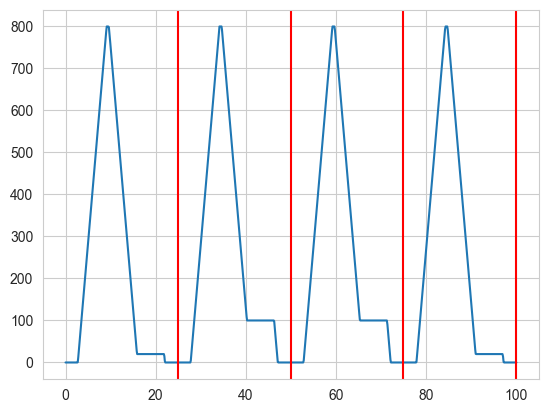

In [104]:
# interpolate frame_timestamp to time and steps
frame_steps = np.interp(frame_timestamp - 0.28, time/1000, steps)
plt.plot(frame_timestamp, frame_steps)
# plot vertical lines every at 25, 50, 75 and 100
plt.axvline(x=25, color='r')
plt.axvline(x=50, color='r')
plt.axvline(x=75, color='r')
plt.axvline(x=100, color='r')

In [17]:
# in the data_path directory, create a folder called frames_snapsoths and save the frames in video_frames as jpeg
# files
temp_path = os.path.join(data_path, 'frames_snapshots')
if not os.path.exists(temp_path):
    os.makedirs(temp_path)

for idx, frame in enumerate(video_frames):
    frame_path = os.path.join(temp_path, 'frame_' + str(idx) + '.jpeg')
    cv2.imwrite(frame_path, frame)

In [7]:
def import_data_frame(filename):

    df = pd.read_hdf(filename)
    df.columns = df.columns.droplevel(0)

    return df

In [61]:
df = import_data_frame(os.path.join(model_path, df_filename))

# import matlab structure from the data_path
matlab_filename = session + '.mat'
matlab_data = scipy.io.loadmat(os.path.join(model_path, matlab_filename))

In [64]:
steps = matlab_data['data']['steps'][0][0][0]
time = matlab_data['data']['time'][0][0][0]

print(time[-1])

87142


In [11]:
def get_DLC_points(dataframe, idx=0):

    up = np.array([dataframe['up']['x'][idx], dataframe['up']['y'][idx]])
    right = np.array([dataframe['right']['x'][idx], dataframe['right']['y'][idx]])
    bottom = np.array([dataframe['down']['x'][idx], dataframe['down']['y'][idx]])
    left = np.array([dataframe['Left']['x'][idx], dataframe['Left']['y'][idx]])
    center = np.array([dataframe['center']['x'][idx], dataframe['center']['y'][idx]])

    return up, right, bottom, left, center

def get_ellipse_axes(dataframe, idx=0):

    up, right, bottom, left, center = get_DLC_points(dataframe, idx)

    # get the major axis and minor axis
    vertical_distance = np.linalg.norm(up - bottom)
    horizontal_distance = np.linalg.norm(right - left)

    # for the horizontal axis, get the rotation
    theta = np.arctan2(right[1] - left[1], right[0] - left[0])

    return vertical_distance, horizontal_distance, theta

def get_ellipse_coordinates(dataframe, idx=0):

    center = np.array([dataframe['center']['x'][idx], dataframe['center']['y'][idx]])
    vertical_distance, horizontal_distance, theta = get_ellipse_axes(dataframe, idx)

    t = np.linspace(0, 2 * np.pi, 100)
    x = center[0] + (horizontal_distance / 2) * np.cos(theta) * np.cos(t) - (vertical_distance / 2) * np.sin(theta) * np.sin(t)
    y = center[1] + (horizontal_distance / 2) * np.sin(theta) * np.cos(t) + (vertical_distance / 2) * np.cos(theta) * np.sin(t)

    return x, y

def compute_area(dataframe, idx=0):

    vertical_distance, horizontal_distance, _ = get_ellipse_axes(dataframe, idx)

    return np.pi * vertical_distance * horizontal_distance

def write_ellipse_video(dataframe, video_frames):

    # Initialize the video writer
    frame_rate = 10  # Frames per second
    frame_width, frame_height = np.size(video_frames[0], 1), np.size(video_frames[0], 0)  # Resolution of the video
    video_out = cv2.VideoWriter('annotated_ellipse_2.mp4', cv2.VideoWriter_fourcc(*'mp4v'), frame_rate, (frame_width, frame_height))

    # Create the animation and save each frame to the video
    num_frames = np.size(video_frames, 0)  # Number of frames in the video

    fig, ax = plt.subplots()
    plot_frame_with_ellipse(dataframe, video_frames, ax, 0)

    for i in range(num_frames):
        # print the frame number in the same line
        print('Frame number ' + str(i), end='\r')

        capture_frame(dataframe, video_frames, ax, video_out, fig, i)

    # Release the video writer and close the plot
    video_out.release()
    plt.close()

def plot_frame_with_ellipse(dataframe, video_frames, ax, frame):
    # Create the plot
    ax.clear()

    up, right, bottom, left, center = get_DLC_points(dataframe, frame)
    x, y = get_ellipse_coordinates(dataframe, frame)

    # Plot contour of ellipse
    ax.plot(x, y, 'b-', label='Ellipse')
    ax.fill(x, y, 'y', alpha=0.1)

    # now plot the actual frame
    ax.imshow(video_frames[frame])

    # Plot points
    ax.plot(center[0], center[1], 'ro', label='Center')
    ax.plot(up[0], up[1], 'go', label='Up')
    ax.plot(right[0], right[1], 'go', label='Right')
    ax.plot(bottom[0], bottom[1], 'go', label='Bottom')
    ax.plot(left[0], left[1], 'go', label='Left')

    # Plot axes
    ax.plot([left[0], right[0]], [left[1], right[1]], 'purple', linestyle='--', alpha=0.5)
    ax.plot([bottom[0], up[0]], [bottom[1], up[1]], 'purple', linestyle='--', alpha=0.5)

    # Add labels and grid
    ax.axis('equal')
    # set axis off
    ax.axis('off')

# Function to capture the plot and convert it to an image
def capture_frame(dataframe, video_frames, ax, video_out, fig, frame):

    plot_frame_with_ellipse(dataframe, video_frames, ax, frame)
    plt.draw()

    frame_width, frame_height = np.size(video_frames[frame], 1), np.size(video_frames[frame], 0)

    # Convert the canvas to an image (RGB format)
    fig.canvas.draw()
    img = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8)
    img = img.reshape(fig.canvas.get_width_height()[::-1] + (3,))

    # Convert RGB to BGR (OpenCV format)
    img_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)

    # # Resize the image to match video resolution
    img_resized = cv2.resize(img_bgr, (frame_width, frame_height))

    # Write the frame to the video
    video_out.write(img_resized)


[518.52941176 531.17647059 543.94117647 555.80769231 568.41176471
 581.11764706 593.73076923 606.45098039 618.29411765 630.94117647
 643.70588235 656.11538462 668.80392157 680.88235294 693.52941176
 706.29411765 718.5        731.15686275 743.47058824 756.11764706]


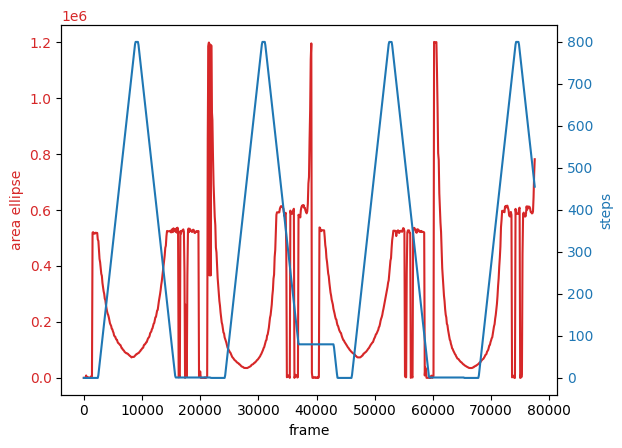

In [63]:
idx = 30

# make a frame_timestamp, where every frame in the video has a corresponding timestamp taking into account 10hz framerate
frame_timestamp = np.arange(0, 100 * np.size(video_frames, 0), 100)

delta = 100

frame_timestamp = frame_timestamp

# interpolate steps to frame_steps
frame_steps = np.interp(frame_timestamp, time, steps)

# compute area of the ellipse for all frames
area_ellipse = []
for idx in range(np.size(video_frames, 0)):
    area_ellipse.append(compute_area(df, idx))

# plot the area of the ellipse and the steps in different y axis
fig, ax1 = plt.subplots()

color = 'tab:red'
ax1.set_xlabel('frame')
ax1.set_ylabel('area ellipse', color=color)

ax1.plot(frame_timestamp, area_ellipse, color=color)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('steps', color=color)
ax2.plot(frame_timestamp, frame_steps, color=color)
ax2.tick_params(axis='y', labelcolor=color)

In [ ]:

x, y = get_ellipse_coordinates(df, idx)
up, right, bottom, left, center = get_DLC_points(df, idx)

plt.plot(up[0], up[1], 'ro')
plt.plot(right[0], right[1], 'ro')
plt.plot(bottom[0], bottom[1], 'ro')
plt.plot(left[0], left[1], 'ro')
plt.plot(x, y)

plt.imshow(video_frames[idx])

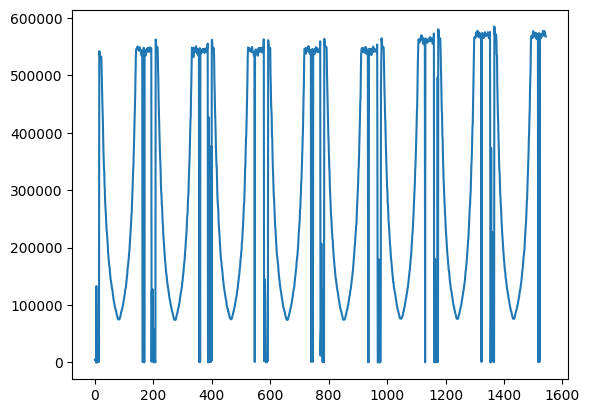

In [230]:
area_ellipse = []

for idx in range(np.size(video_frames, 0)):
    area_ellipse.append(compute_area(df, idx))

plt.plot(area_ellipse)

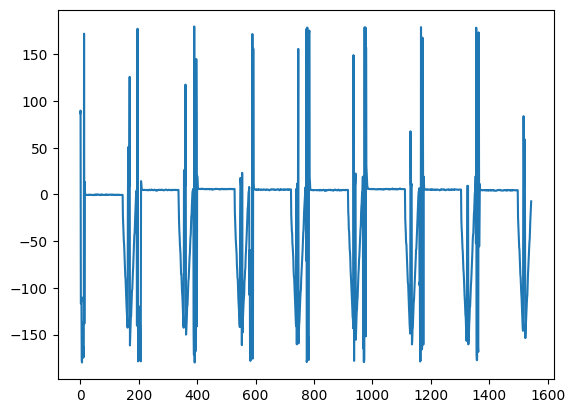

In [191]:
theta_video = []
for idx in range(np.size(video_frames, 0)):
    _, _, theta = get_ellipse_axes(df, idx)
    theta_video.append(theta)

plt.plot(theta_video)